# Redes Neuronales V — Notebook 01
## Construcción del dataset facial y preprocesamiento de imágenes

**Objetivo.** Construir y preparar el dataset facial para una red siamesa:

1. Organización y control del dataset (una carpeta por persona, registro de consentimiento).
2. **Detección** de rostros con MTCNN (caja + 5 puntos faciales).
3. **Alineación** por la línea de los ojos, **recorte** con margen y **redimensionado** a 160×160 (entrada de FaceNet).
4. **Control de calidad**: número de rostros, confianza de detección, nitidez (varianza del Laplaciano) y brillo.
5. **Partición**: identidades de entrenamiento (60 % galería/entrenamiento, 40 % prueba) e identidades **no vistas** reservadas para las pruebas *zero-shot*.
6. **Aumento de datos** para entrenamiento.

### Dataset y consentimiento
Se usa la **base de datos de rostros ORL / AT&T** (*The Database of Faces*, Olivetti Research Laboratory, Cambridge, 1992-1994): 40 personas × 10 fotografías de 92×112 píxeles en escala de grises, tomadas con fines de investigación en reconocimiento facial, con variaciones de iluminación, expresión (ojos abiertos/cerrados, sonrisa), gafas y ligera rotación. Es una base pública de uso académico; su uso exige dar crédito al Olivetti Research Laboratory (Samaria y Harter, 1994).

El mismo código funciona con un dataset propio: basta con `FUENTE = "propio"` y una carpeta `dataset_propio/<persona>/<foto>.jpg` con fotografías de personas que hayan autorizado su uso académico. En ese caso conviene `PUBLICAR_ROSTROS = False` para que las figuras muestren los rostros pixelados.


In [ ]:
# En Google Colab: instalar dependencias (una vez por sesión)
!pip install -q deepface tf-keras mtcnn

In [1]:
import os, sys, json, time, zipfile, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2

FUENTE = "orl"                       # "orl" (base pública ORL/AT&T) o "propio" (fotos con consentimiento)
DATA_DIR = "dataset_orl" if FUENTE == "orl" else "dataset_propio"   # <carpeta>/<persona>/<foto>
OUT_DIR = "procesado"                # salida (no se sube a GitHub)
PUBLICAR_ROSTROS = FUENTE == "orl"   # base pública: se muestran; fotos propias: se pixelan
FRACCION_NO_VISTAS = 0.25            # fracción de identidades reservadas para zero-shot
SEED = 42
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})

In [2]:
# Obtención del dataset
if not os.path.isdir(DATA_DIR):
    if FUENTE == "orl":
        # Copia pública de la base ORL/AT&T en GitHub (40 carpetas s1..s40 con 10 imágenes .pgm)
        import urllib.request
        from concurrent.futures import ThreadPoolExecutor
        BASE = "https://raw.githubusercontent.com/milk-abc/PCA-KPCA/master/att_faces"
        jobs = [(f"{BASE}/s{s}/{i}.pgm", f"{DATA_DIR}/s{s}/{i}.pgm") for s in range(1, 41) for i in range(1, 11)]
        for _, dst in jobs: os.makedirs(os.path.dirname(dst), exist_ok=True)
        with ThreadPoolExecutor(16) as ex: list(ex.map(lambda j: urllib.request.urlretrieve(*j), jobs))
        print("Descargadas", len(jobs), "imágenes ORL")
    else:
        from google.colab import files
        print("Suba dataset_propio.zip ..."); up = files.upload()
        for name in up:
            zipfile.ZipFile(name).extractall(".")

### Módulo de preprocesamiento (`src/faces.py`)

In [3]:
from __future__ import annotations
"""Preprocesamiento de imágenes faciales: detección, alineación, recorte, control de calidad y aumentos.

Flujo por imagen:
    leer (EXIF) -> RGB -> detectar rostro (MTCNN) -> alinear por los ojos -> recortar con margen
    -> redimensionar a 160x160 -> [estandarizar al pasar por el encoder]
"""

import os
from dataclasses import dataclass, field

import cv2
import numpy as np
from PIL import Image, ImageOps

IMG_SIZE = 160                      # entrada de FaceNet
VALID_EXT = (".jpg", ".jpeg", ".png", ".webp", ".bmp", ".pgm")


@dataclass
class FaceRecord:
    """Resultado del preprocesamiento de una foto."""
    person: str
    path: str
    face: np.ndarray | None = None            # rostro alineado 160x160x3 uint8
    confidence: float = 0.0
    n_faces: int = 0
    blur: float = 0.0                          # varianza del Laplaciano (nitidez)
    brightness: float = 0.0
    face_px: int = 0                           # ancho de la caja del rostro en la foto original
    status: str = "ok"
    notes: list = field(default_factory=list)


def read_image(path: str, max_side: int = 1024) -> np.ndarray:
    """Lee la imagen respetando la orientación EXIF del móvil y la reduce si es muy grande."""
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    if max(img.size) > max_side:
        img.thumbnail((max_side, max_side), Image.LANCZOS)
    return np.asarray(img)


def align_face(img: np.ndarray, left_eye, right_eye) -> tuple[np.ndarray, np.ndarray]:
    """Rota la imagen para que la línea entre los ojos quede horizontal. Devuelve imagen y matriz."""
    dy, dx = right_eye[1] - left_eye[1], right_eye[0] - left_eye[0]
    angle = np.degrees(np.arctan2(dy, dx))
    center = ((left_eye[0] + right_eye[0]) / 2.0, (left_eye[1] + right_eye[1]) / 2.0)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)
    rotated = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)
    return rotated, M


def crop_square(img: np.ndarray, box, margin: float = 0.2, size: int = IMG_SIZE) -> np.ndarray:
    """Recorte cuadrado centrado en la caja del rostro con un margen relativo; redimensiona a size x size."""
    x, y, w, h = box
    cx, cy, side = x + w / 2, y + h / 2, max(w, h) * (1 + margin)
    x1, y1 = int(round(cx - side / 2)), int(round(cy - side / 2))
    x2, y2 = x1 + int(round(side)), y1 + int(round(side))
    pad = max(0, -x1, -y1, x2 - img.shape[1], y2 - img.shape[0])
    if pad:
        img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_REFLECT)
        x1, y1, x2, y2 = x1 + pad, y1 + pad, x2 + pad, y2 + pad
    return cv2.resize(img[y1:y2, x1:x2], (size, size), interpolation=cv2.INTER_AREA)


class FacePreprocessor:
    """Detecta (MTCNN), alinea y recorta rostros; calcula métricas de calidad."""

    def __init__(self, min_confidence: float = 0.90, margin: float = 0.2, min_face_px: int = 60):
        from mtcnn import MTCNN                       # import diferido: es pesado
        self.detector = MTCNN()
        self.min_confidence, self.margin, self.min_face_px = min_confidence, margin, min_face_px

    def detect(self, img):
        dets = [d for d in self.detector.detect_faces(img) if d["confidence"] >= self.min_confidence]
        return sorted(dets, key=lambda d: d["box"][2] * d["box"][3], reverse=True)   # mayor primero

    def process(self, path: str, person: str) -> FaceRecord:
        rec = FaceRecord(person=person, path=path)
        img = read_image(path)
        dets = self.detect(img)
        rec.n_faces = len(dets)
        if not dets:
            rec.status = "sin_rostro"
            return rec
        if len(dets) > 1:
            rec.notes.append(f"{len(dets)} rostros: se usa el más grande")
        d = dets[0]
        rec.confidence, rec.face_px = float(d["confidence"]), int(d["box"][2])
        kp = d["keypoints"]
        # en MTCNN 'left_eye' es el ojo que aparece a la izquierda de la imagen
        rotated, M = align_face(img, kp["left_eye"], kp["right_eye"])
        x, y, w, h = d["box"]
        cx, cy = M @ np.array([x + w / 2, y + h / 2, 1.0])        # centro de la caja tras la rotación
        rec.face = crop_square(rotated, (cx - w / 2, cy - h / 2, w, h), self.margin)
        gray = cv2.cvtColor(rec.face, cv2.COLOR_RGB2GRAY)
        rec.blur = float(cv2.Laplacian(gray, cv2.CV_64F).var())
        rec.brightness = float(gray.mean())
        if rec.face_px < self.min_face_px:
            rec.notes.append("rostro pequeño")
        return rec


def natkey(s: str):
    """Orden natural: s2 antes que s10."""
    import re
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]


def list_dataset(root: str) -> dict[str, list[str]]:
    """{persona: [rutas]} a partir de root/<persona>/<imagen>."""
    people = {}
    for person in sorted(os.listdir(root), key=natkey):
        pdir = os.path.join(root, person)
        if os.path.isdir(pdir) and not person.startswith((".", "_")):
            files = sorted((os.path.join(pdir, f) for f in os.listdir(pdir) if f.lower().endswith(VALID_EXT)), key=natkey)
            if files:
                people[person] = files
    return people


def standardize(faces: np.ndarray) -> np.ndarray:
    """Estandarización por imagen (prewhitening de FaceNet): media 0 y desviación 1 en cada rostro."""
    x = faces.astype("float32")
    mean = x.mean(axis=(1, 2, 3), keepdims=True)
    std = np.maximum(x.std(axis=(1, 2, 3), keepdims=True), 1.0 / np.sqrt(x[0].size))
    return (x - mean) / std


def augment(face: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Aumento de datos fotométrico y geométrico leve (sólo para entrenamiento)."""
    img = face.astype("float32")
    if rng.random() < 0.5:
        img = img[:, ::-1]                                               # espejo horizontal
    angle, scale = rng.uniform(-10, 10), rng.uniform(0.95, 1.08)         # rotación y zoom leves
    tx, ty = rng.uniform(-6, 6, size=2)
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, scale); M[:, 2] += (tx, ty)
    img = cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), borderMode=cv2.BORDER_REFLECT)
    img = img * rng.uniform(0.75, 1.25) + rng.uniform(-25, 25)           # contraste y brillo
    if rng.random() < 0.2:
        img = cv2.GaussianBlur(img, (3, 3), 0)
    return np.clip(img, 0, 255).astype("uint8")


def anonymize(face: np.ndarray, blocks: int = 8) -> np.ndarray:
    """Pixela un rostro para figuras públicas cuando no hay permiso de publicar la imagen."""
    small = cv2.resize(face, (blocks, blocks), interpolation=cv2.INTER_LINEAR)
    return cv2.resize(small, face.shape[:2][::-1], interpolation=cv2.INTER_NEAREST)

In [4]:
def show(face):
    """Rostro para figuras: original o pixelado según PUBLICAR_ROSTROS."""
    return face if PUBLICAR_ROSTROS else anonymize(face)

## 1. Inventario del dataset

In [5]:
people = list_dataset(DATA_DIR)
inv = []
for person, files in people.items():
    sizes = [Image.open(f).size for f in files]
    inv.append({"persona": person, "fotos": len(files),
                "resolución mín.": f"{min(sizes)[0]}×{min(sizes)[1]}", "resolución máx.": f"{max(sizes)[0]}×{max(sizes)[1]}"})
inv_df = pd.DataFrame(inv).set_index("persona")
print(f"{len(people)} personas · {inv_df['fotos'].sum()} fotografías")
inv_df

40 personas · 400 fotografías


,fotos,resolución mín.,resolución máx.
persona,,,
s1,10,92×112,92×112
s2,10,92×112,92×112
s3,10,92×112,92×112
s4,10,92×112,92×112
s5,10,92×112,92×112
s6,10,92×112,92×112
s7,10,92×112,92×112
s8,10,92×112,92×112
s9,10,92×112,92×112


## 2. Detección, alineación y recorte
Se ilustra el proceso completo sobre una foto y luego se aplica a todo el dataset.

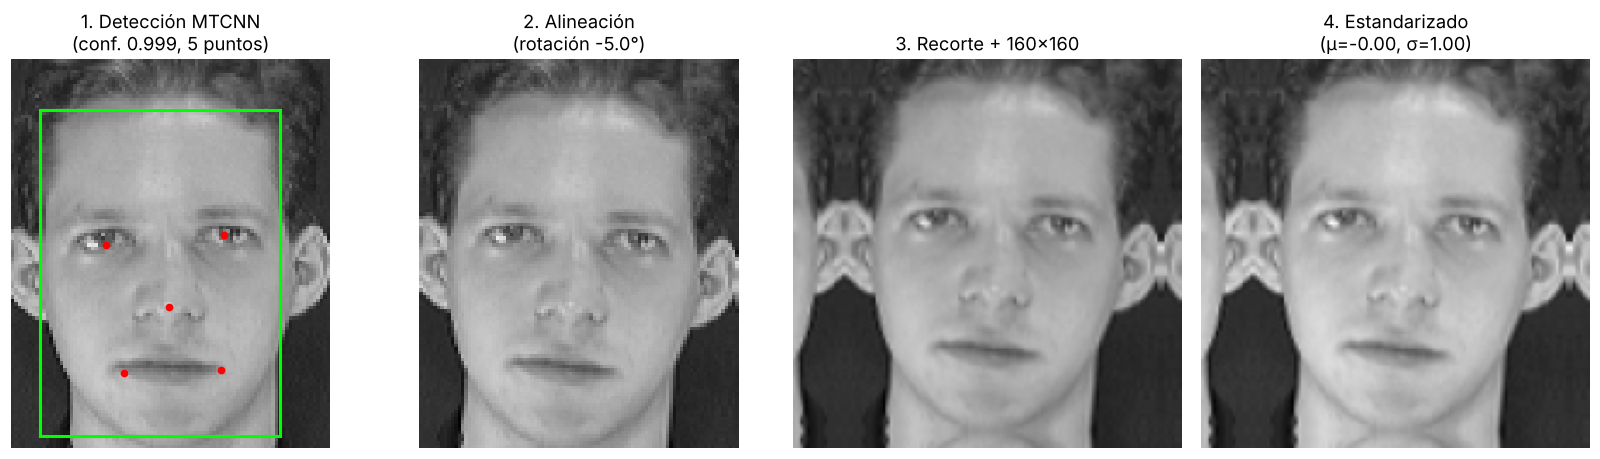

In [6]:
fp = FacePreprocessor(min_confidence=0.90, margin=0.20)
demo_path = next(iter(people.values()))[0]
img = read_image(demo_path)
det = fp.detect(img)[0]
rot, M = align_face(img, det["keypoints"]["left_eye"], det["keypoints"]["right_eye"])
rec = fp.process(demo_path, "demo")
std_face = standardize(rec.face[None])[0]

fig, ax = plt.subplots(1, 4, figsize=(15, 4.2))
x, y, w, h = det["box"]
crop_view = img.copy()
if not PUBLICAR_ROSTROS:                                  # pixelar sólo la región del rostro
    crop_view[y:y + h, x:x + w] = anonymize(crop_view[y:y + h, x:x + w], 10)
ax[0].imshow(crop_view); ax[0].add_patch(patches.Rectangle((x, y), w, h, fill=False, ec="lime", lw=2))
for k, (px, py) in det["keypoints"].items(): ax[0].plot(px, py, "r.", ms=8)
ax[0].set_title(f"1. Detección MTCNN\n(conf. {det['confidence']:.3f}, 5 puntos)")
angle = np.degrees(np.arctan2(det["keypoints"]["right_eye"][1] - det["keypoints"]["left_eye"][1],
                              det["keypoints"]["right_eye"][0] - det["keypoints"]["left_eye"][0]))
ax[1].imshow(show(rot if max(rot.shape) <= 400 else cv2.resize(rot, (img.shape[1] // 4, img.shape[0] // 4)))); ax[1].set_title(f"2. Alineación\n(rotación {angle:.1f}°)")
ax[2].imshow(show(rec.face)); ax[2].set_title("3. Recorte + 160×160")
ax[3].imshow(show(((std_face - std_face.min()) / (std_face.max() - std_face.min()) * 255).astype("uint8")))
ax[3].set_title(f"4. Estandarizado\n(μ={std_face.mean():.2f}, σ={std_face.std():.2f})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("figures/01_pipeline.png", bbox_inches="tight"); plt.show()

In [7]:
t0 = time.time()
records = [fp.process(f, person) for person, files in people.items() for f in files]
print(f"Procesadas {len(records)} imágenes en {time.time() - t0:.1f} s")
q = pd.DataFrame([{"persona": r.person, "archivo": os.path.basename(r.path), "estado": r.status, "rostros": r.n_faces,
                   "confianza": r.confidence, "nitidez": r.blur, "brillo": r.brightness, "ancho_rostro_px": r.face_px,
                   "notas": "; ".join(r.notes)} for r in records])
q.round(3).head(10)

Procesadas 400 imágenes en 30.7 s


,persona,archivo,estado,rostros,confianza,nitidez,brillo,ancho_rostro_px,notas
0,s1,1.pgm,ok,1,0.999,225.799,120.949,69,
1,s1,2.pgm,ok,1,0.998,137.403,140.423,88,
2,s1,3.pgm,ok,1,0.994,217.373,121.940,73,
3,s1,4.pgm,ok,1,0.999,163.672,128.893,85,
4,s1,5.pgm,ok,1,1.000,167.068,129.831,83,
5,s1,6.pgm,ok,1,0.996,250.394,136.304,80,
6,s1,7.pgm,ok,1,0.998,200.888,123.679,76,
7,s1,8.pgm,ok,1,0.998,191.032,111.945,72,
8,s1,9.pgm,ok,1,1.000,209.232,121.379,77,
9,s1,10.pgm,ok,1,0.998,167.911,119.998,78,


## 3. Control de calidad
* **Sin rostro**: se descarta.
* **Varios rostros**: se conserva el de mayor tamaño (se registra en notas).
* **Nitidez**: varianza del Laplaciano del recorte; valores muy bajos indican desenfoque. Se marca como borrosa (y se descarta) la imagen con nitidez inferior al 25 % de la mediana del dataset.
* **Brillo** medio del recorte (0–255) para detectar sub/sobreexposición.

In [8]:
ok = q["estado"] == "ok"
blur_thr = 0.25 * float(q.loc[ok, "nitidez"].median())          # relativo al dataset
q["borrosa"] = ok & (q["nitidez"] < blur_thr)
q["usable"] = ok & ~q["borrosa"]
summary = q.groupby("persona").agg(fotos=("archivo", "size"), sin_rostro=("estado", lambda s: (s != "ok").sum()),
                                    varios_rostros=("rostros", lambda s: (s > 1).sum()), borrosas=("borrosa", "sum"),
                                    usables=("usable", "sum"), confianza_media=("confianza", "mean"),
                                    nitidez_mediana=("nitidez", "median"), brillo_medio=("brillo", "mean"))
print(f"Umbral de nitidez: {blur_thr:.1f}")
summary.round(3)

Umbral de nitidez: 54.2


,fotos,sin_rostro,varios_rostros,borrosas,usables,confianza_media,nitidez_mediana,brillo_medio
persona,,,,,,,,
s1,10,0,0,0,10,0.998,195.960,125.534
s10,10,0,0,0,10,0.998,172.987,103.910
s11,10,0,0,0,10,0.998,449.717,97.141
s12,10,0,0,0,10,0.999,183.950,113.489
s13,10,0,0,0,10,0.999,317.700,119.922
s14,10,0,0,0,10,0.997,438.250,98.267
s15,10,0,0,0,10,0.996,294.898,108.624
s16,10,0,0,0,10,0.992,316.248,112.521
s17,10,0,0,0,10,0.991,286.249,112.362


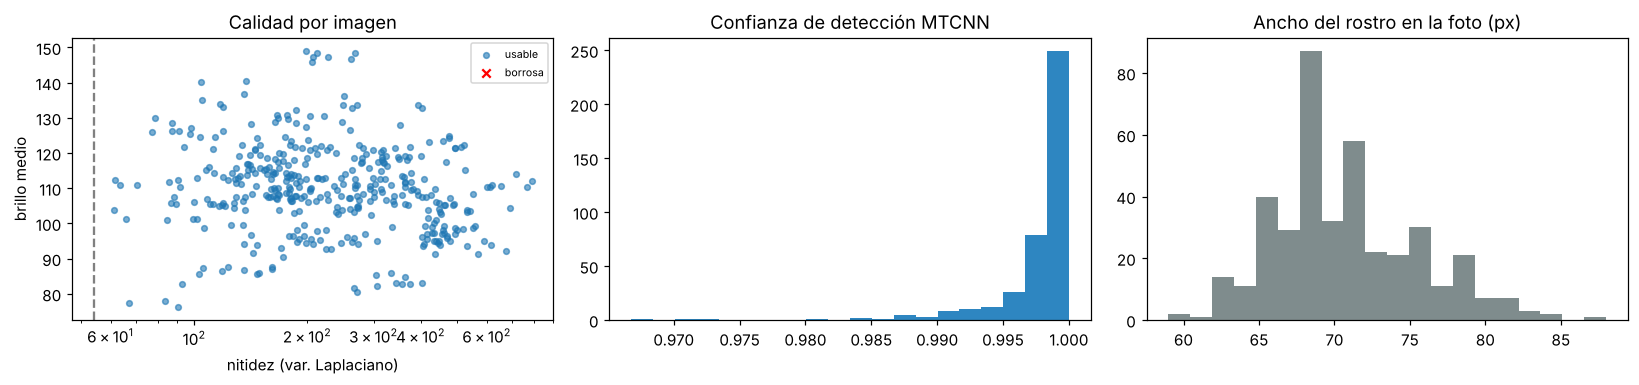

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].scatter(q.loc[ok & ~q["borrosa"], "nitidez"], q.loc[ok & ~q["borrosa"], "brillo"], s=14, alpha=0.6, label="usable")
ax[0].scatter(q.loc[q["borrosa"], "nitidez"], q.loc[q["borrosa"], "brillo"], s=30, c="red", marker="x", label="borrosa")
ax[0].axvline(blur_thr, ls="--", c="gray"); ax[0].set_xscale("log"); ax[0].set_xlabel("nitidez (var. Laplaciano)"); ax[0].set_ylabel("brillo medio")
ax[0].set_title("Calidad por imagen"); ax[0].legend(fontsize=7)
ax[1].hist(q.loc[ok, "confianza"], bins=20, color="#2e86c1"); ax[1].set_title("Confianza de detección MTCNN")
ax[2].hist(q.loc[ok, "ancho_rostro_px"], bins=20, color="#7f8c8d"); ax[2].set_title("Ancho del rostro en la foto (px)")
plt.tight_layout(); plt.savefig("figures/01_calidad.png", bbox_inches="tight"); plt.show()

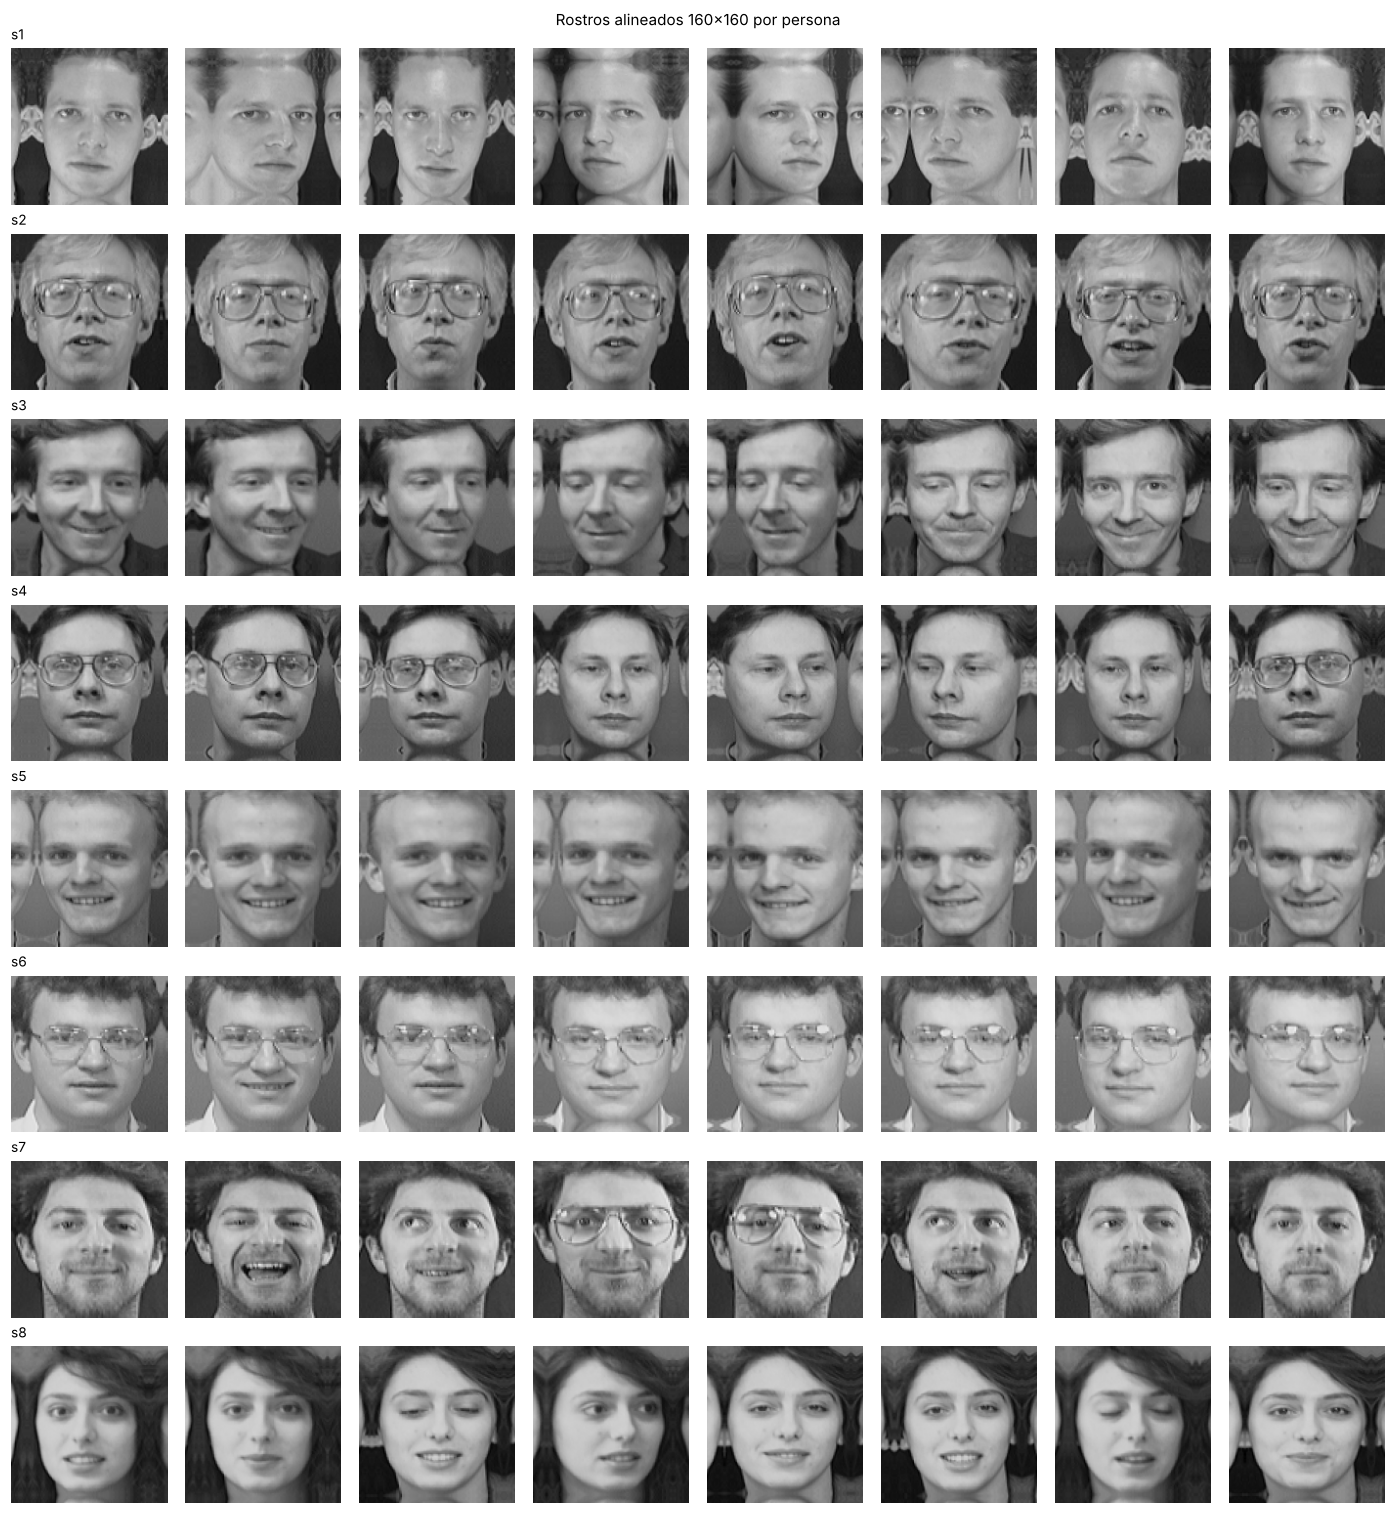

In [10]:
usable = [r for r, u in zip(records, q["usable"]) if u]
names = sorted(people, key=natkey)
show_names = names[:8]                                    # muestra de 8 personas
n_show = 8
fig, axes = plt.subplots(len(show_names), n_show, figsize=(1.6 * n_show, 1.75 * len(show_names)))
axes = np.atleast_2d(axes)
for i, person in enumerate(show_names):
    faces_p = [r.face for r in usable if r.person == person][:n_show]
    for j in range(n_show):
        axes[i, j].axis("off")
        if j < len(faces_p): axes[i, j].imshow(show(faces_p[j]))
    axes[i, 0].set_title(person, fontsize=9, loc="left")
plt.suptitle("Rostros alineados 160×160 por persona" + ("" if PUBLICAR_ROSTROS else " (pixelados para publicación)"), fontsize=10)
plt.tight_layout(); plt.savefig("figures/01_rostros_por_persona.png", bbox_inches="tight"); plt.show()

## 4. Partición del dataset
* **Identidades no vistas (zero-shot):** un 25 % de las personas (elegidas al azar con semilla fija) se excluye por completo del entrenamiento de la red siamesa. Sirven para comprobar que el modelo reconoce identidades que nunca vio al entrenar.
* Para las demás, por persona: **60 % galería/entrenamiento** (de aquí salen las fotos de enrolamiento en one-shot y few-shot) y **40 % prueba**. Partir *por persona* garantiza que todas las identidades estén en ambos conjuntos.

In [11]:
rng = np.random.default_rng(SEED)
n_nv = max(1, int(round(FRACCION_NO_VISTAS * len(names)))) if len(names) >= 3 else 0
NO_VISTAS = sorted(rng.choice(names, n_nv, replace=False).tolist(), key=natkey) if n_nv else []
split = []
for person in names:
    idx = [i for i, r in enumerate(usable) if r.person == person]
    idx = list(rng.permutation(idx))
    if person in NO_VISTAS:
        split += [(i, "no_vista") for i in idx]
    else:
        n_tr = max(1, int(round(0.6 * len(idx))))
        split += [(i, "train") for i in idx[:n_tr]] + [(i, "test") for i in idx[n_tr:]]
split = sorted(split)
faces = np.stack([usable[i].face for i, _ in split])
labels_txt = np.array([usable[i].person for i, _ in split])
subset = np.array([s for _, s in split])
paths = np.array([usable[i].path for i, _ in split])
np.savez_compressed(f"{OUT_DIR}/rostros.npz", faces=faces, labels=labels_txt, subset=subset, paths=paths,
                    no_vista=",".join(NO_VISTAS))
part = pd.crosstab(pd.Series(labels_txt, name="persona"), pd.Series(subset, name="conjunto")).reindex(columns=["train", "test", "no_vista"], fill_value=0)
part = part.loc[sorted(part.index, key=natkey)]
print(f"Identidades de entrenamiento: {len(names) - len(NO_VISTAS)} | no vistas (zero-shot): {len(NO_VISTAS)} -> {NO_VISTAS}")
print("Imágenes por conjunto:", part.sum().to_dict())
part.T

Identidades de entrenamiento: 30 | no vistas (zero-shot): 10 -> ['s3', 's4', 's8', 's15', 's16', 's22', 's25', 's27', 's31', 's40']
Imágenes por conjunto: {'train': 179, 'test': 120, 'no_vista': 100}


persona,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,...,s31,s32,s33,s34,s35,s36,s37,s38,s39,s40
conjunto,,,,,,,,,,,,,,,,,,,,,
train,6,6,0,0,6,6,6,0,6,6,...,0,6,6,6,6,6,5,6,6,0
test,4,4,0,0,4,4,4,0,4,4,...,0,4,4,4,4,4,4,4,4,0
no_vista,0,0,10,10,0,0,0,10,0,0,...,10,0,0,0,0,0,0,0,0,10


## 5. Aumento de datos (sólo para entrenamiento)
Con pocas fotos por persona, el aumento genera variaciones realistas: espejo horizontal, rotación ±10°, zoom 0.95–1.08, desplazamiento ±6 px, contraste ×0.75–1.25, brillo ±25 y desenfoque ocasional. No se aplica a las imágenes de prueba.

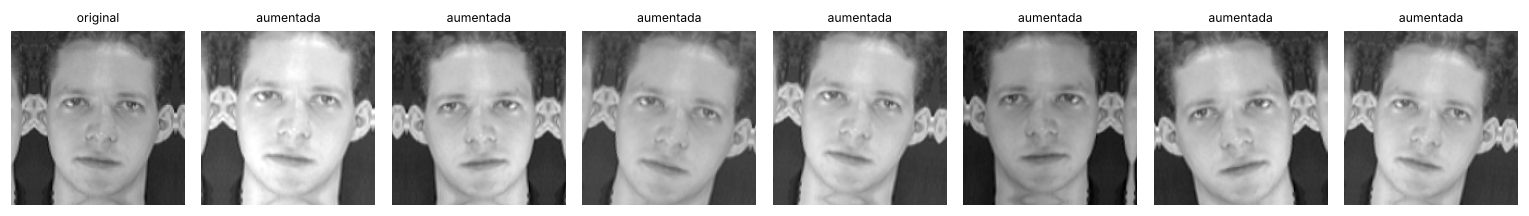

In [12]:
rng = np.random.default_rng(SEED)
base = faces[subset == "train"][0]
fig, axes = plt.subplots(1, 8, figsize=(14, 2.1))
axes[0].imshow(show(base)); axes[0].set_title("original", fontsize=8)
for a in axes[1:]:
    a.imshow(show(augment(base, rng))); a.set_title("aumentada", fontsize=8)
for a in axes: a.axis("off")
plt.tight_layout(); plt.savefig("figures/01_aumentos.png", bbox_inches="tight"); plt.show()

In [13]:
res = {"fuente": FUENTE, "personas": len(names), "fotos": int(inv_df["fotos"].sum()), "usables": len(usable),
       "descartadas_sin_rostro": int((q["estado"] != "ok").sum()), "borrosas": int(q["borrosa"].sum()),
       "umbral_nitidez": blur_thr, "no_vistas": NO_VISTAS, "imagenes_por_conjunto": part.sum().to_dict(),
       "particion": part.reset_index().to_dict("records"),
       "calidad": summary.reset_index().round(4).to_dict("records")}
json.dump(res, open("results/01_dataset.json", "w"), indent=2, ensure_ascii=False, default=float)
print(json.dumps({k: v for k, v in res.items() if k not in ("particion", "calidad")}, ensure_ascii=False, indent=1))

{
 "fuente": "orl",
 "personas": 40,
 "fotos": 400,
 "usables": 399,
 "descartadas_sin_rostro": 1,
 "borrosas": 0,
 "umbral_nitidez": 54.165200191879265,
 "no_vistas": [
  "s3",
  "s4",
  "s8",
  "s15",
  "s16",
  "s22",
  "s25",
  "s27",
  "s31",
  "s40"
 ],
 "imagenes_por_conjunto": {
  "train": 179,
  "test": 120,
  "no_vista": 100
 }
}


## 6. Conclusiones
* Se procesaron las **400 fotografías** de 40 personas: MTCNN detectó un rostro en **399** (confianza mínima 0.967); una imagen se descartó por no detectarse rostro. Ninguna quedó por debajo del umbral de nitidez (25 % de la mediana).
* La **alineación** corrigió inclinaciones de hasta varios grados (−5° en el ejemplo), de modo que todos los rostros llegan al encoder con los ojos horizontales y a la misma escala (160×160).
* Como las fotos ORL están muy ajustadas al rostro (92×112 px), el recorte con 20 % de margen sale del marco y se completa por reflexión; esto añade bordes artificiales, pero afecta por igual a todas las imágenes.
* Partición: **30 identidades de entrenamiento** (179 imágenes de entrenamiento/galería y 120 de prueba) y **10 identidades no vistas** (100 imágenes) que nunca participan en el entrenamiento y se usan para las pruebas *zero-shot*.